In [ ]:
# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

=========== Complete Stock Analyzer =============


Enter the stock symbol (or 'Quit' to exit): HDFCBANK.NS



 --------------------------------
 Company : HDFC Bank Limited
 Current Price : 736.7 INR
 Change: +11.20 (+1.54%)

 --------------------------------


Enter the start date (yyyy-mm-dd): 2024-7-10
Enter the end date (yyyy-mm-dd): 2026-06-13


[*********************100%***********************]  1 of 1 completed


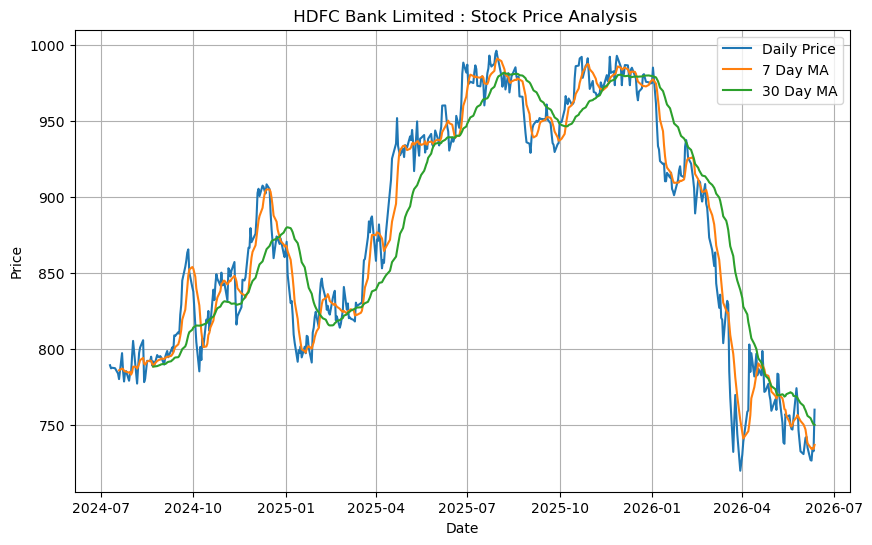

In [ ]:
print("=========== Complete Stock Analyzer =============")

while True:

    symbol = input("Enter the stock symbol (or 'Quit' to exit):").upper()

    if symbol == "QUIT":
        print("Exiting Program. Thanks for using.")
        break

    try:
        stock = yf.Ticker(symbol)
        info = stock.info


        name = info.get("longName","N/A")
        price = info.get("currentPrice")
        prev_close = info.get("previousClose")
        currency = info.get("currency","USD")

        print("\n --------------------------------")
        print(f" Company : {name}")
        print(f" Current Price : {price} {currency}")

        if price and prev_close:
            change = price - prev_close
            percent = (change/prev_close)*100

            print(f" Change: {change:+.2f} ({percent:+.2f}%)")

        print("\n --------------------------------")

        start_date = input("Enter the start date (yyyy-mm-dd):")
        end_date = input("Enter the end date (yyyy-mm-dd):")

        df = yf.download(symbol, start = start_date, end = end_date, interval="1d")
        df["7_day_MA"] = df["Close"].rolling(window=7).mean()
        df["30_day_MA"] = df["Close"].rolling(window=30).mean()

        #Plot the graph

        plt.figure(figsize=(10,6))
        plt.plot(df["Close"],label = "Daily Price")
        plt.plot(df["7_day_MA"], label= "7 Day MA")
        plt.plot(df["30_day_MA"], label = "30 Day MA")
        plt.title(f" {name} : Stock Price Analysis")
        plt.xlabel("Date")
        plt.ylabel("Price")
        plt.legend()
        plt.grid(True)
        plt.show()


    except Exception as e:
        print("Invalid Symbol or Network Error")

